# Sistema Eletromecânico
para baixar o editor de equacoes
https://www.wiris.com/en/mathtype/


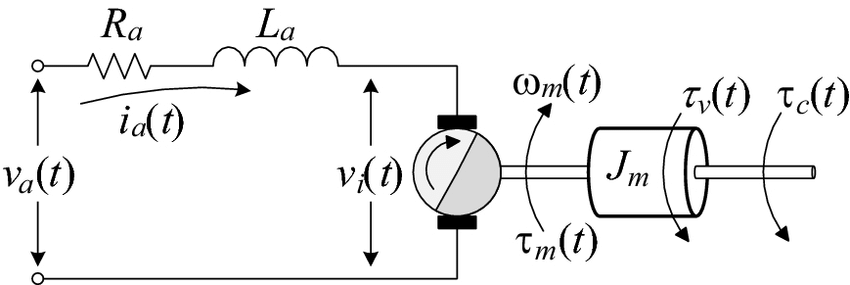




Um sistema motor-carga é descrito pelo seguinte sistema de EDOs:
$$\left[ {\begin{array}{*{20}{c}}
{i'}\\
{\omega '}
\end{array}} \right] = \left[ {\begin{array}{*{20}{c}}
{ - \frac{R}{L}}&{ - \frac{k}{L}}\\
{\frac{k}{J}}&{ - \frac{\gamma }{J}}
\end{array}} \right]\left[ {\begin{array}{*{20}{c}}
i\\
\omega 
\end{array}} \right] + \left[ {\begin{array}{*{20}{c}}
{\frac{v}{L}}\\
{\frac{0}{J}}
\end{array}} \right]$$

Com as condições iniciais:
$$\left[ {\begin{array}{*{20}{c}}
{i\left( 0 \right)}\\
{\omega \left( 0 \right)}
\end{array}} \right] = \left[ {\begin{array}{*{20}{c}}
{10}\\
{50}
\end{array}} \right]$$

In [245]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [246]:
R = sp.Rational(1,10)
L = sp.Rational(1,100)
J = sp.Rational(1,10)
k = sp.Rational(1,2)
g = sp.Rational(1,1)
Vm = 250
Tc = 10
i0 = 0
w0 = 0

### Condições iniciais

In [247]:
WI0 = sp.Matrix([[i0],
                 [w0]])
WI0

Matrix([
[0],
[0]])

### Fontes

In [248]:
F = sp.Matrix([[sp.Rational(Vm,L)],
               [sp.Rational(Tc,J)]])
F

Matrix([
[25000],
[  100]])

### Matriz dos coeficientes

In [249]:
import numpy as np
M = sp.Matrix([[-R/L, -k/L], 
               [k/J, -g/J]])
M

Matrix([
[-10, -50],
[  5, -10]])

In [250]:
P, D = M.diagonalize()

In [251]:
P

Matrix([
[-sqrt(10)*I, sqrt(10)*I],
[          1,          1]])

In [252]:
D

Matrix([
[-10 - 5*sqrt(10)*I,                  0],
[                 0, -10 + 5*sqrt(10)*I]])

In [253]:
c1,c2,t = sp.symbols('c1 c2 t')

In [254]:
Y = sp.exp(D*t)
Y.simplify()

Matrix([
[exp(-5*t*(2 + sqrt(10)*I)),                          0],
[                         0, exp(-5*t*(2 - sqrt(10)*I))]])

In [255]:
C = sp.Matrix([c1, c2])
C

Matrix([
[c1],
[c2]])

In [256]:
X_part = P * Y
sp.simplify(X_part*C)

Matrix([
[sqrt(10)*I*(-c1 + c2*exp(10*sqrt(10)*I*t))*exp(-5*t*(2 + sqrt(10)*I))],
[            (c1 + c2*exp(10*sqrt(10)*I*t))*exp(-5*t*(2 + sqrt(10)*I))]])

### Solução em regime permanente
Como as fontes não variam, em regime permanente as grandezas já não variam mais, assim:

$$\left[ {\begin{array}{*{20}{c}}
0\\
0
\end{array}} \right] = \left[ {\begin{array}{*{20}{c}}
{ - R}&{ - k}\\
k&{ - \gamma }
\end{array}} \right]\left[ {\begin{array}{*{20}{c}}
{{i_\infty }}\\
{{\omega _\infty }}
\end{array}} \right] + \left[ {\begin{array}{*{20}{c}}
{{V_f}}\\
{{T_m}}
\end{array}} \right]$$

In [257]:
X_forc = - M.inv() * F
X_forc.evalf()

Matrix([
[700.0],
[360.0]])

In [258]:
X0 = (P * Y).subs(t, 0)
X0

Matrix([
[-sqrt(10)*I, sqrt(10)*I],
[          1,          1]])

In [259]:
C = X0.inv() * (WI0 - X_forc)
C.evalf()

Matrix([
[-180.0 - 110.679718105893*I],
[-180.0 + 110.679718105893*I]])

In [260]:
X_total = X_part*C + X_forc
X_total = sp.simplify(X_total)
X_total

Matrix([
[5*(140*exp(20*t) + sqrt(10)*I*(36 + 7*sqrt(10)*I)*exp(5*t*(2 - sqrt(10)*I)) + sqrt(10)*I*(-36 + 7*sqrt(10)*I)*exp(5*t*(2 + sqrt(10)*I)))*exp(-20*t)],
[                       5*(72*exp(20*t) - (36 + 7*sqrt(10)*I)*exp(5*t*(2 - sqrt(10)*I)) + (-36 + 7*sqrt(10)*I)*exp(5*t*(2 + sqrt(10)*I)))*exp(-20*t)]])

In [261]:
ii = X_total[0]
ww = X_total[1]

In [265]:
ii_num = sp.lambdify(t, ii)
ww_num = sp.lambdify(t, ww)
tt_num = np.linspace(0, 2, 100000)

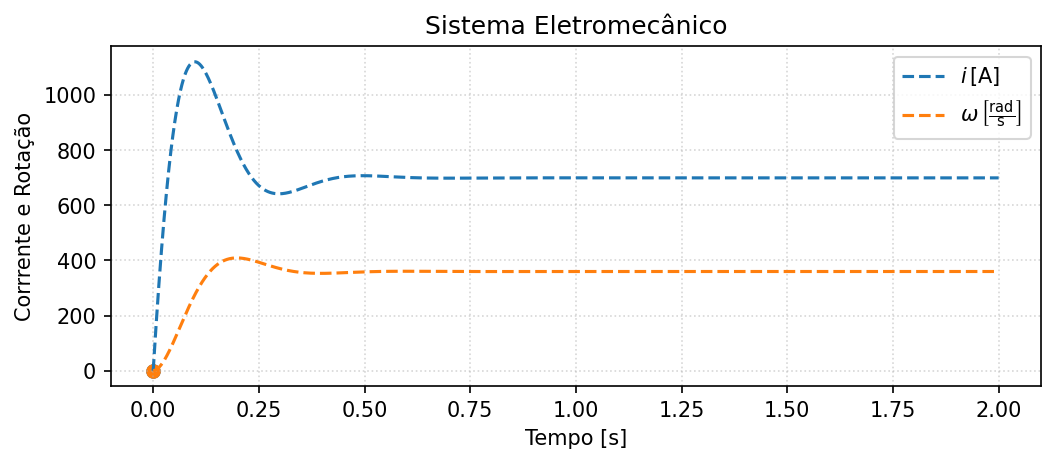

In [266]:
plt.figure(figsize=(8,3), dpi=150)
plt.plot(tt_num, np.real(ii_num(tt_num)), label=r'$i \, \rm{[A]}$', ls='--')
plt.plot(tt_num, np.real(ww_num(tt_num)), label=r'$\omega \, \rm{\left[ \frac{rad}{s} \right]}$', ls='--')
plt.scatter(0, i0)
plt.scatter(0, w0)
plt.xlabel('Tempo [s]')
plt.ylabel('Corrrente e Rotação')
plt.title('Sistema Eletromecânico')
plt.legend()
plt.grid(alpha=0.5, ls=":")
plt.show()

E a parte imaginária?

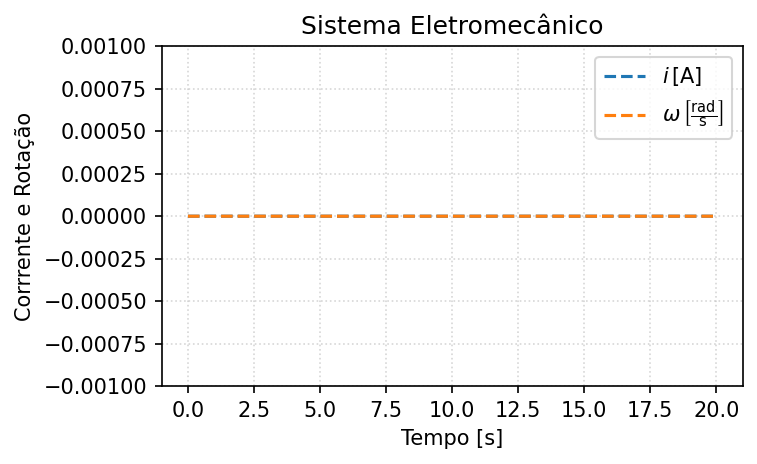

In [264]:
plt.figure(figsize=(5,3), dpi=150)
plt.plot(tt_num, np.imag(ii_num(tt_num)), label=r'$i \, \rm{[A]}$', ls='--')
plt.plot(tt_num, np.imag(ww_num(tt_num)), label=r'$\omega \, \rm{\left[ \frac{rad}{s} \right]}$', ls='--')
plt.xlabel('Tempo [s]')
plt.ylabel('Corrrente e Rotação')
plt.title('Sistema Eletromecânico')
plt.legend()
plt.grid(alpha=0.5, ls=":")
plt.ylim(-0.001, 0.001)
plt.show()